# Análise exploratória – dados educacionais do RMI

Notebook complementar ao projeto dbt. O objetivo **não** é gerar insights sobre a rede
(os dados são anonimizados e aleatorizados), e sim entender grão, chaves, qualidade e
distribuições para justificar as decisões tomadas nos models e testes.

**Reprodução**: baixe os Parquets do bucket público para `../data/` (ver README) e execute
as células em ordem. Só usa `pandas`, `numpy` e `matplotlib`.

Estrutura:
1. Carga e visão geral
2. Grão e chaves de cada tabela
3. Integridade referencial (órfãos)
4. Duplicatas
5. Distribuições e anomalias
6. Como isso influenciou o projeto dbt


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

DATA = Path("../data")
PALETTE = {"azul": "#2a78d6", "laranja": "#eb6834", "verde": "#1baf7a", "amarelo": "#eda100"}

def estilo(ax, titulo):
    ax.set_title(titulo, loc="left", fontsize=11, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)

tabelas = {t: pd.read_parquet(DATA / f"{t}.parquet") for t in ["aluno", "escola", "turma", "frequencia", "avaliacao"]}
# id_aluno chega como BYTES: padronizamos para hex (mesma regra da macro aluno_id_to_string do dbt)
for t in ["aluno", "turma", "frequencia", "avaliacao"]:
    tabelas[t]["id_aluno"] = tabelas[t]["id_aluno"].map(lambda b: b.hex() if isinstance(b, (bytes, bytearray)) else b)
aluno, escola, turma, freq, aval = (tabelas[k] for k in ["aluno", "escola", "turma", "frequencia", "avaliacao"])


## 1. Visão geral

Tamanho, tipos e nulos de cada tabela.

In [2]:
resumo = pd.DataFrame({
    "linhas": {t: len(df) for t, df in tabelas.items()},
    "colunas": {t: df.shape[1] for t, df in tabelas.items()},
    "colunas_com_nulos": {t: int((df.isna().sum() > 0).sum()) for t, df in tabelas.items()},
    "memoria_mb": {t: round(df.memory_usage(deep=True).sum() / 1e6, 1) for t, df in tabelas.items()},
})
resumo

,linhas,colunas,colunas_com_nulos,memoria_mb
aluno,97044,4,1,6.8
escola,1558,2,0,0.0
turma,97044,3,0,5.6
frequencia,2727684,7,0,332.8
avaliacao,221687,8,5,21.9


In [3]:
for t, df in tabelas.items():
    print(f"== {t}")
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "nulos": df.isna().sum(), "distintos": df.nunique()}))
    print()

== aluno
                dtype  nulos  distintos
id_aluno          str      0      97044
id_turma        int64      0      17311
faixa_etaria      str      0          5
bairro        float64     68       1069

== escola
           dtype  nulos  distintos
id_escola  int64      0       1558
bairro     int64      0        169

== turma
          dtype  nulos  distintos
ano       int64      0          1
id_turma  int64      0      17311
id_aluno    str      0      97044

== frequencia


               dtype  nulos  distintos
id_escola      int64      0        521
id_aluno         str      0      97044
id_turma       int64      0       5516
data_inicio      str      0         11
data_fim         str      0         11
disciplina       str      0          4
frequencia   float64      0        137

== avaliacao
                dtype   nulos  distintos
id_aluno          str       0      69502
id_turma        int64       0      11546
frequencia    float64    1734       1901
bimestre          str       0          4
disciplina_1  float64   34609       1733
disciplina_2  float64   35931       1723
disciplina_3  float64  221687          0
disciplina_4  float64   35462       1739



**Observações de tipagem que viraram regra de staging**

* `id_aluno` é `BYTES` (34 bytes) em todas as tabelas → convertido para `STRING` hex (`to_hex`) na macro `aluno_id_to_string`.
* `aluno.bairro` é `FLOAT64` apenas porque tem 68 nulos → `CAST AS INT64` no staging.
* `frequencia.data_inicio/data_fim` são `STRING` → `SAFE.PARSE_DATE`.
* `avaliacao.bimestre` é `STRING` ('1'..'4') → `INT64`.
* `avaliacao.disciplina_3` (Inglês) é **100 % nula**: mantida por contrato, ignorada nas médias.


## 2. Grão e chaves

O nome da tabela nem sempre descreve o grão. Verificamos empiricamente.

In [4]:
checagens = {
    "aluno: id_aluno único": aluno["id_aluno"].is_unique,
    "escola: id_escola único": escola["id_escola"].is_unique,
    "turma: id_aluno único (1 linha por aluno!)": turma["id_aluno"].is_unique,
    "turma: linhas == alunos": len(turma) == len(aluno),
    "turma.id_turma == aluno.id_turma para todo aluno": (
        aluno.merge(turma, on="id_aluno")[["id_turma_x", "id_turma_y"]].nunique(axis=1).eq(1).all()
    ),
    "turma.ano único": turma["ano"].nunique() == 1,
    "frequencia: 4 disciplinas por aluno/período": freq.groupby(["id_aluno", "data_inicio"])["disciplina"].nunique().eq(4).all(),
}
pd.Series(checagens, name="resultado").to_frame()

,resultado
aluno: id_aluno único,True
escola: id_escola único,True
turma: id_aluno único (1 linha por aluno!),True
turma: linhas == alunos,True
turma.id_turma == aluno.id_turma para todo aluno,True
turma.ano único,True
frequencia: 4 disciplinas por aluno/período,True


**Conclusão**: `turma` é, na prática, a **matrícula** aluno→turma do ano letivo (1 linha por aluno), não um cadastro de
turmas com série/turno. No dbt o model `stg_educacao__turma` documenta isso e o mart de turma usa a
**faixa etária predominante** como proxy de série. Tamanho das turmas:

count    17311.0
mean         5.6
std          9.9
min          1.0
25%          1.0
50%          2.0
75%          4.0
max        118.0
dtype: float64


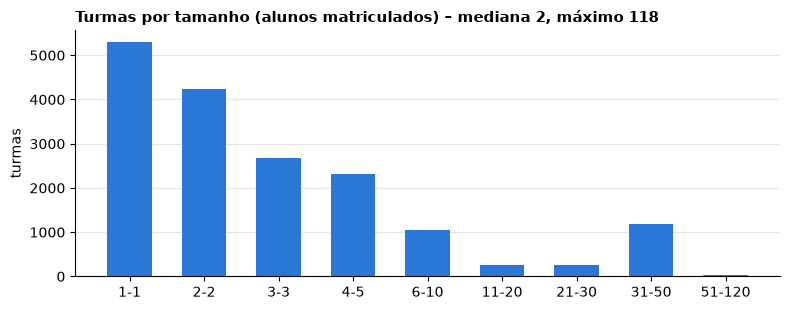

In [5]:
tam = turma.groupby("id_turma").size()
print(tam.describe().round(1))
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = [0, 1, 2, 3, 5, 10, 20, 30, 50, 120]
contagem = pd.cut(tam, bins=bins).value_counts().sort_index()
ax.bar(range(len(contagem)), contagem.values, color=PALETTE["azul"], width=0.6)
ax.set_xticks(range(len(contagem)), [f"{int(i.left)+1}-{int(i.right)}" for i in contagem.index])
ax.set_ylabel("turmas")
estilo(ax, "Turmas por tamanho (alunos matriculados) – mediana 2, máximo 118")
plt.tight_layout(); plt.show()

## 3. Integridade referencial

Percentual de linhas da tabela filha cuja chave existe na tabela pai.

In [6]:
def cobertura(filha, col_f, pai, col_p):
    return round(filha[col_f].isin(pai[col_p]).mean() * 100, 2)

integridade = pd.Series({
    "frequencia.id_aluno -> aluno": cobertura(freq, "id_aluno", aluno, "id_aluno"),
    "frequencia.id_escola -> escola": cobertura(freq, "id_escola", escola, "id_escola"),
    "frequencia.id_turma -> turma": cobertura(freq, "id_turma", turma, "id_turma"),
    "avaliacao.id_aluno -> aluno": cobertura(aval, "id_aluno", aluno, "id_aluno"),
    "avaliacao.id_turma -> turma": cobertura(aval, "id_turma", turma, "id_turma"),
    "aluno.bairro -> escola.bairro (hash)": cobertura(aluno.dropna(subset=["bairro"]), "bairro", escola, "bairro"),
}, name="% linhas com pai existente").to_frame()
integridade

,% linhas com pai existente
frequencia.id_aluno -> aluno,100.00
frequencia.id_escola -> escola,100.00
frequencia.id_turma -> turma,87.59
avaliacao.id_aluno -> aluno,100.00
avaliacao.id_turma -> turma,99.92
aluno.bairro -> escola.bairro (hash),0.00


In [7]:
# A turma informada na frequência/avaliação coincide com a turma de matrícula do aluno?
fa = freq[["id_aluno", "id_turma"]].drop_duplicates().merge(aluno[["id_aluno", "id_turma"]], on="id_aluno", suffixes=("_freq", "_matricula"))
aa = aval[["id_aluno", "id_turma"]].drop_duplicates().merge(aluno[["id_aluno", "id_turma"]], on="id_aluno", suffixes=("_aval", "_matricula"))
pd.Series({
    "frequencia: turma == turma de matrícula (%)": round((fa.id_turma_freq == fa.id_turma_matricula).mean() * 100, 2),
    "avaliacao: turma == turma de matrícula (%)": round((aa.id_turma_aval == aa.id_turma_matricula).mean() * 100, 2),
    "alunos com >1 escola na frequência (%)": round((freq.groupby("id_aluno")["id_escola"].nunique() > 1).mean() * 100, 2),
    "alunos do cadastro com frequência (%)": round(aluno.id_aluno.isin(freq.id_aluno).mean() * 100, 2),
    "alunos do cadastro com avaliação (%)": round(aluno.id_aluno.isin(aval.id_aluno).mean() * 100, 2),
    "escolas do cadastro com frequência (%)": round(escola.id_escola.isin(freq.id_escola).mean() * 100, 2),
}).to_frame("valor")

,valor
frequencia: turma == turma de matrícula (%),0.01
avaliacao: turma == turma de matrícula (%),90.84
alunos com >1 escola na frequência (%),3.59
alunos do cadastro com frequência (%),100.00
alunos do cadastro com avaliação (%),71.62
escolas do cadastro com frequência (%),33.44


**Decisões derivadas**

* `relationships` de `frequencia.id_turma → turma` fica com `severity: warn`: 12 % de órfãos são um fato da fonte, não um bug novo.
* A turma da frequência **quase nunca** é a turma de matrícula (0,01 %) → `id_turma` **não entra no grão** de
  `int_educacao__aluno_frequencia_periodo`; o grão é aluno × escola × período.
* A avaliação não tem `id_escola`. Como 100 % dos alunos têm frequência (com escola), criamos
  `int_educacao__aluno_escola` (escola com mais períodos) para ligar avaliação → escola. 3,6 % dos alunos
  trocam de escola e recebem `flag_transferencia`.
* O hash de bairro do aluno **nunca** coincide com o da escola (salts diferentes), e nenhum dos dois casa com
  `datario.dados_mestres.bairro`. Bairro só serve como chave de agrupamento anônima ("região").
* 66 % das escolas do cadastro não têm nenhum aluno com frequência → o mart mantém todas (reconciliação de
  contagem) e marca `flag_escola_sem_alunos`.


## 4. Duplicatas

In [8]:
dups = pd.Series({
    "frequencia: linhas 100% idênticas": int(freq.duplicated().sum()),
    "frequencia: mesmo (aluno, turma, escola, disciplina, período)": int(freq.duplicated(["id_aluno", "id_turma", "id_escola", "disciplina", "data_inicio"]).sum()),
    "frequencia: mesmo (aluno, disciplina, período) – turmas distintas": int(freq.duplicated(["id_aluno", "disciplina", "data_inicio"]).sum()),
    "avaliacao: mesmo (aluno, turma, bimestre)": int(aval.duplicated(["id_aluno", "id_turma", "bimestre"]).sum()),
    "avaliacao: mesmo (aluno, bimestre) – turmas distintas": int(aval.duplicated(["id_aluno", "bimestre"]).sum()),
}).to_frame("linhas")
dups

,linhas
frequencia: linhas 100% idênticas,1483
"frequencia: mesmo (aluno, turma, escola, disciplina, período)",2576
"frequencia: mesmo (aluno, disciplina, período) – turmas distintas",63284
"avaliacao: mesmo (aluno, turma, bimestre)",34
"avaliacao: mesmo (aluno, bimestre) – turmas distintas",581


In [9]:
# As duplicatas de grão em frequencia que NÃO são idênticas têm valores diferentes?
chave = ["id_aluno", "id_turma", "id_escola", "disciplina", "data_inicio"]
sem_exatas = freq.drop_duplicates()
conflito = sem_exatas[sem_exatas.duplicated(chave, keep=False)].sort_values(chave)
print("linhas em conflito (mesmo grão, valor diferente):", len(conflito))
conflito.groupby(chave)["frequencia"].agg(["min", "max", "count"]).head(8)

linhas em conflito (mesmo grão, valor diferente): 2186


min    max  count
id_aluno                           id_turma             id_escola            disciplina   data_inicio                         
007d69553ab4b19a0805547e9ccf344e5e -5643942021581575715 -6093448452292301480 disciplina_1 2000-05-10   99.733333  100.0      2
                                                                             disciplina_2 2000-05-10   99.600000  100.0      2
                                                                             disciplina_3 2000-05-10   99.866667  100.0      2
                                                                             disciplina_4 2000-05-10   99.466667  100.0      2
00b6917a778aa1b7ffdfc71f8a31637e38  3028339542019934381 -7657571723586763481 disciplina_1 2000-05-10   99.933333  100.0      2
                                                                             disciplina_3 2000-05-10   99.866667  100.0      2
                                                                             disciplina_4 2000-05-10   99.866667  100.0      2
0304cb9f2a4e2a164b18395244051389d5  4467480264156077414  3119373222148343675 disciplina_1 2000-05-10   99.666667  100.0      2

**Decisões derivadas**

* Staging de frequência faz `SELECT DISTINCT` (remove só as 1.483 cópias exatas) e deixa o conflito visível:
  o teste de unicidade do grão fica em `warn`, e o intermediate resolve com `AVG`.
* Staging de avaliação deduplica com `ROW_NUMBER` (mantém a linha com mais notas preenchidas) e expõe
  `qtd_registros_fonte` para auditoria.


## 5. Distribuições e anomalias

### 5.1 Duas medidas de frequência que não contam a mesma história

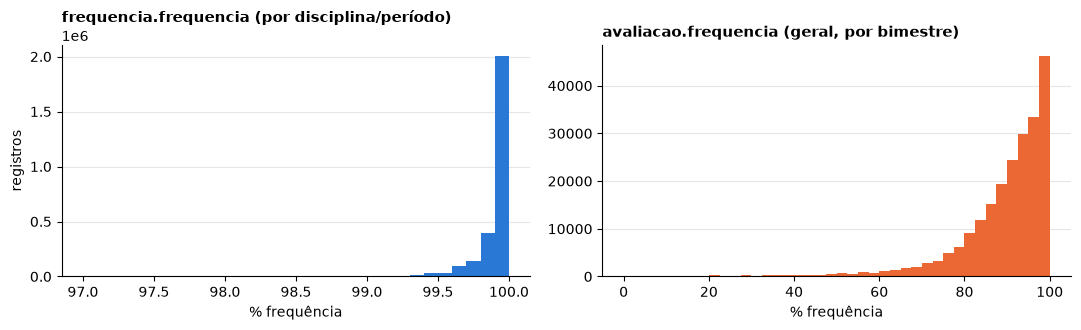

,frequencia.frequencia,avaliacao.frequencia
count,2727684.00,219953.00
mean,99.93,89.10
std,0.14,12.17
min,97.33,0.00
25%,99.89,85.71
50%,100.00,92.44
75%,100.00,96.86
max,100.00,100.00


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(freq["frequencia"], bins=np.linspace(97, 100, 31), color=PALETTE["azul"])
estilo(axes[0], "frequencia.frequencia (por disciplina/período)")
axes[0].set_xlabel("% frequência"); axes[0].set_ylabel("registros")
axes[1].hist(aval["frequencia"].dropna(), bins=np.linspace(0, 100, 41), color=PALETTE["laranja"])
estilo(axes[1], "avaliacao.frequencia (geral, por bimestre)")
axes[1].set_xlabel("% frequência")
plt.tight_layout(); plt.show()

pd.DataFrame({
    "frequencia.frequencia": freq["frequencia"].describe(),
    "avaliacao.frequencia": aval["frequencia"].describe(),
}).round(2)

In [11]:
limiar = 75
freq_anual = aval.groupby("id_aluno")["frequencia"].mean()
print(f"alunos com frequência bimestral: {freq_anual.notna().sum():,}")
print(f"alunos com média anual < {limiar}%: {(freq_anual < limiar).sum():,} ({(freq_anual < limiar).mean()*100:.1f}%)")
print(f"registros da tabela frequencia abaixo de {limiar}%: {(freq['frequencia'] < limiar).sum()}")

alunos com frequência bimestral: 68,735
alunos com média anual < 75%: 7,155 (10.3%)
registros da tabela frequencia abaixo de 75%: 0


A tabela `frequencia` tem variância quase nula (mínimo 97,3 %): a fórmula `100 - faltas/dias_letivos` da
anonimização comprime tudo perto de 100 e **nenhum** registro fica abaixo de 75 %. Já `avaliacao.frequencia`
(frequência geral do bimestre) tem distribuição realista, com cauda à esquerda.

**Decisão**: o indicador de absenteísmo crônico do mart usa a **média anual de `avaliacao.frequencia`**;
a tabela `frequencia` entra apenas como indicador complementar (`percentual_frequencia_disciplinas_medio`)
e como fonte da escola do aluno. O limiar de 75 % é `var('limiar_frequencia_minima')`.


### 5.2 Notas: pico artificial em zero

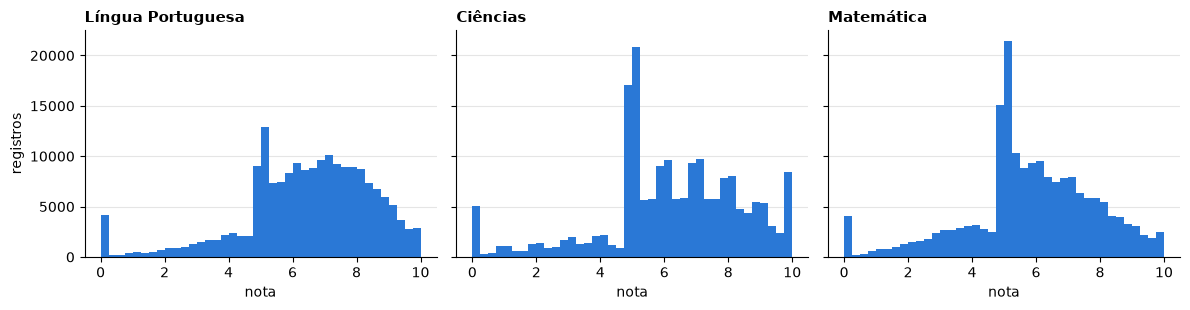

,linhas
registros sem nenhuma nota,33050
"registros com todas as notas existentes <= 0,5",1624
"registros com nota em [0, 0.5] em Português",4375
"registros com nota em (0.5, 1] em Português",661


In [12]:
notas = ["disciplina_1", "disciplina_2", "disciplina_4"]
nomes = {"disciplina_1": "Língua Portuguesa", "disciplina_2": "Ciências", "disciplina_4": "Matemática"}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, c in zip(axes, notas):
    ax.hist(aval[c].dropna(), bins=np.linspace(0, 10, 41), color=PALETTE["azul"])
    estilo(ax, nomes[c]); ax.set_xlabel("nota")
axes[0].set_ylabel("registros")
plt.tight_layout(); plt.show()

zeradas = aval[notas].le(0.5).all(axis=1) & aval[notas].notna().any(axis=1)
pd.Series({
    "registros sem nenhuma nota": int(aval[notas].isna().all(axis=1).sum()),
    "registros com todas as notas existentes <= 0,5": int(zeradas.sum()),
    "registros com nota em [0, 0.5] em Português": int(aval["disciplina_1"].le(0.5).sum()),
    "registros com nota em (0.5, 1] em Português": int(aval["disciplina_1"].between(0.5, 1, inclusive="right").sum()),
}).to_frame("linhas")

Há um pico isolado em `[0, 0.5]` muito maior que o degrau seguinte: é o padrão de **"sem nota" codificado como 0**
e depois deslocado pelo jitter de ±0,2 da anonimização. Como não dá para distinguir com certeza de um zero real,
o intermediate **não exclui** esses registros; cria `flag_notas_zeradas` e o mart expõe `qtd_registros_notas_zeradas`
para que o analista decida. As notas ficam sempre em `[0, 10]` (testes `accepted_range`).


### 5.3 Cobertura temporal da frequência

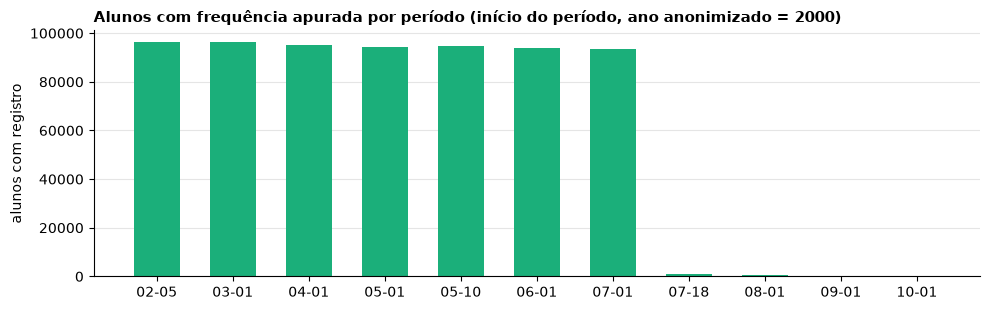

,data_inicio,data_fim,registros,alunos
0,2000-02-05,2000-02-28,398112,96350
1,2000-03-01,2000-03-31,397920,96213
2,2000-04-01,2000-04-30,386820,95139
3,2000-05-01,2000-05-09,379480,94441
4,2000-05-10,2000-05-31,399244,94761
5,2000-06-01,2000-06-30,383804,94014
6,2000-07-01,2000-07-17,375892,93589
7,2000-07-18,2000-07-31,3636,905
8,2000-08-01,2000-08-31,2640,654
9,2000-09-01,2000-09-30,68,17


In [13]:
periodos = freq.groupby(["data_inicio", "data_fim"]).size().rename("registros").reset_index()
periodos["alunos"] = freq.groupby("data_inicio")["id_aluno"].nunique().values
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(len(periodos)), periodos["alunos"], color=PALETTE["verde"], width=0.6)
ax.set_xticks(range(len(periodos)), periodos["data_inicio"].str[5:], rotation=0)
ax.set_ylabel("alunos com registro")
estilo(ax, "Alunos com frequência apurada por período (início do período, ano anonimizado = 2000)")
plt.tight_layout(); plt.show()
periodos

Sete períodos cobrem praticamente toda a rede (fev–jul); de 18/jul em diante restam poucas centenas de alunos.
Os períodos são disjuntos (não se sobrepõem) e sempre `data_fim >= data_inicio` – isso virou o teste singular
`assert_periodos_frequencia_nao_se_sobrepoem` e o `expression_is_true` no staging. O ano é sempre 2000
(`var('ano_letivo')`), verificado pelo teste `assert_frequencia_dentro_do_ano_letivo`.


### 5.4 Bimestres avaliados e faixa etária

bimestres distintos por aluno:
 bimestre
1    11588
2     8234
3     5670
4    44010


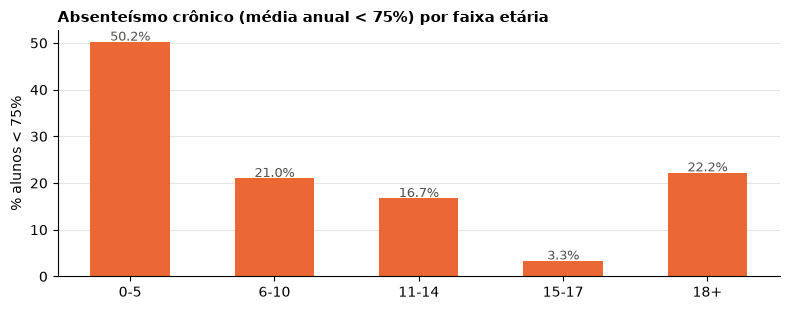

,alunos,freq_media,pct_abaixo_75
faixa_etaria,,,
0-5,3829,69.5,50.2
6-10,5229,83.6,21.0
11-14,5970,85.8,16.7
15-17,47453,90.0,3.3
18+,7021,83.5,22.2


In [14]:
bim_por_aluno = aval.groupby("id_aluno")["bimestre"].nunique().value_counts().sort_index()
print("bimestres distintos por aluno:\n", bim_por_aluno.to_string())

freq_fx = (aval.groupby("id_aluno")["frequencia"].mean().rename("freq_anual").reset_index()
           .merge(aluno[["id_aluno", "faixa_etaria"]], on="id_aluno"))
por_faixa = freq_fx.groupby("faixa_etaria").agg(alunos=("id_aluno", "size"), freq_media=("freq_anual", "mean"),
                                                pct_abaixo_75=("freq_anual", lambda s: (s < 75).mean() * 100))
por_faixa = por_faixa.reindex(["0-5", "6-10", "11-14", "15-17", "18+"]).round(1)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(por_faixa.index, por_faixa["pct_abaixo_75"], color=PALETTE["laranja"], width=0.55)
for i, v in enumerate(por_faixa["pct_abaixo_75"]):
    ax.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9, color="#52514e")
ax.set_ylabel("% alunos < 75%")
estilo(ax, "Absenteísmo crônico (média anual < 75%) por faixa etária")
plt.tight_layout(); plt.show()
por_faixa

Apenas 63 % dos alunos avaliados têm os 4 bimestres. Por isso a média anual é calculada sobre os bimestres
disponíveis e o mart expõe `cobertura_frequencia_bimestral` ao lado da taxa – uma taxa sem denominador
explícito seria enganosa para o gestor.


## 6. Como a EDA moldou o projeto dbt

| Achado | Decisão no dbt |
|---|---|
| `id_aluno` em BYTES | macro `aluno_id_to_string` → STRING hex em todas as camadas |
| `turma` tem 1 linha por aluno | model documentado como matrícula; `unique` em `id_aluno`; mart de turma usa faixa etária como proxy de série |
| turma da frequência ≠ turma de matrícula; 12 % de órfãos | `id_turma` fora do grão do intermediate; `relationships` em `warn` |
| avaliação sem `id_escola` | `int_educacao__aluno_escola` (escola com mais períodos de frequência) |
| 1.483 duplicatas exatas + ~1.100 pares conflitantes em `frequencia` | `DISTINCT` no staging, `AVG` no intermediate, unicidade em `warn` |
| 34 duplicatas em `avaliacao` | `ROW_NUMBER` + `qtd_registros_fonte` |
| `frequencia.frequencia` ∈ [97, 100] | absenteísmo calculado com `avaliacao.frequencia`; tabela de frequência vira indicador complementar |
| pico de notas em ~0 | `flag_notas_zeradas`, sem exclusão |
| `disciplina_3` 100 % nula | coluna mantida por contrato, ignorada nas médias |
| hashes de bairro incompatíveis | bairro só como "região" anonimizada; `datario.bairro` não é usada |
| períodos disjuntos, ano fixo | testes singulares de sobreposição e de ano letivo |
| 66 % das escolas sem alunos | mart mantém todas as escolas + `flag_escola_sem_alunos`; `equal_rowcount` com o cadastro |
